# 03 - Modelling and stress tests

Read the ablation table before the headline AUC, and read the
technical-covariate row before anything else. If that row is not near
chance, nothing below it means what it appears to mean.

> Repeat and permutation counts here are reduced so the notebook runs in a
> few minutes. The numbers quoted in the README come from
> `scripts/02_train_evaluate.py` and `scripts/04_confounder_audit.py` at
> full settings (10 CV repeats, 200 permutations); expect small differences
> in the third decimal here.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from cfdna_insight.features import load_features, split_legacy_technical

FEATURES = '../results/features'

# split_legacy_technical moves chromosome entropy and coverage dispersion out
# of the technical block. They are copy-number readouts, and leaving them in
# the negative control makes it fire for biological reasons.
blocks = split_legacy_technical(load_features(FEATURES))

samples = pd.read_csv(os.path.join(FEATURES, 'samples_used.tsv'), sep='\t')
order = [s for s in samples['sample_id'] if s in blocks['size_summary'].index]
samples = samples.set_index('sample_id').loc[order].reset_index()
y = (samples['label'] == 'cancer').astype(int).to_numpy()

print(f'{len(order)} samples, {y.sum()} cancer, {len(y)-y.sum()} control')
{k: v.shape for k, v in blocks.items()}

[info] moved ['tech_chr_entropy', 'tech_coverage_cv'] from technical -> aneuploidy (they are copy-number readouts, not library metrics)
66 samples, 33 cancer, 33 control


{'coverage': (66, 550),
 'delfi': (66, 550),
 'motif': (66, 256),
 'size_hist': (66, 351),
 'size_summary': (66, 10),
 'technical': (66, 4),
 'window_arms': (66, 550),
 'aneuploidy': (66, 2)}

In [2]:
from cfdna_insight import modeling, plots
from cfdna_insight.cnv import HealthyReference, arm_summary
from IPython.display import Image

# arm-level CNV, built here the way most published work does it: one
# healthy reference over the whole cohort. The leak this introduces is
# measured further down.
ref = HealthyReference.fit(blocks['coverage'].reindex(order)[y == 0])
arms = blocks['window_arms'].reindex(order).iloc[0]
blocks['cnv'] = pd.DataFrame(
    {s: arm_summary(ref.zscore(blocks['coverage'].loc[s]), arms)
     for s in order}).T
blocks['cnv'].shape

(66, 48)

## Ablation

In [3]:
abl = modeling.ablation(blocks, y, order, n_repeats=4)
abl[['label', 'n_features', 'auc_mean', 'auc_lo', 'auc_hi']].round(3)

,label,n_features,auc_mean,auc_lo,auc_hi
5,end motifs only,256,0.890,0.880,0.900
6,all biological,1193,0.858,0.817,0.899
4,aneuploidy proxies only,2,0.855,0.824,0.880
3,CNV arms only,44,0.809,0.782,0.837
2,DELFI profile only,530,0.657,0.620,0.686
7,TECHNICAL ONLY (negative control),3,0.503,0.471,0.550
0,size summary only,10,0.484,0.434,0.567
1,size histogram only,351,0.433,0.346,0.507


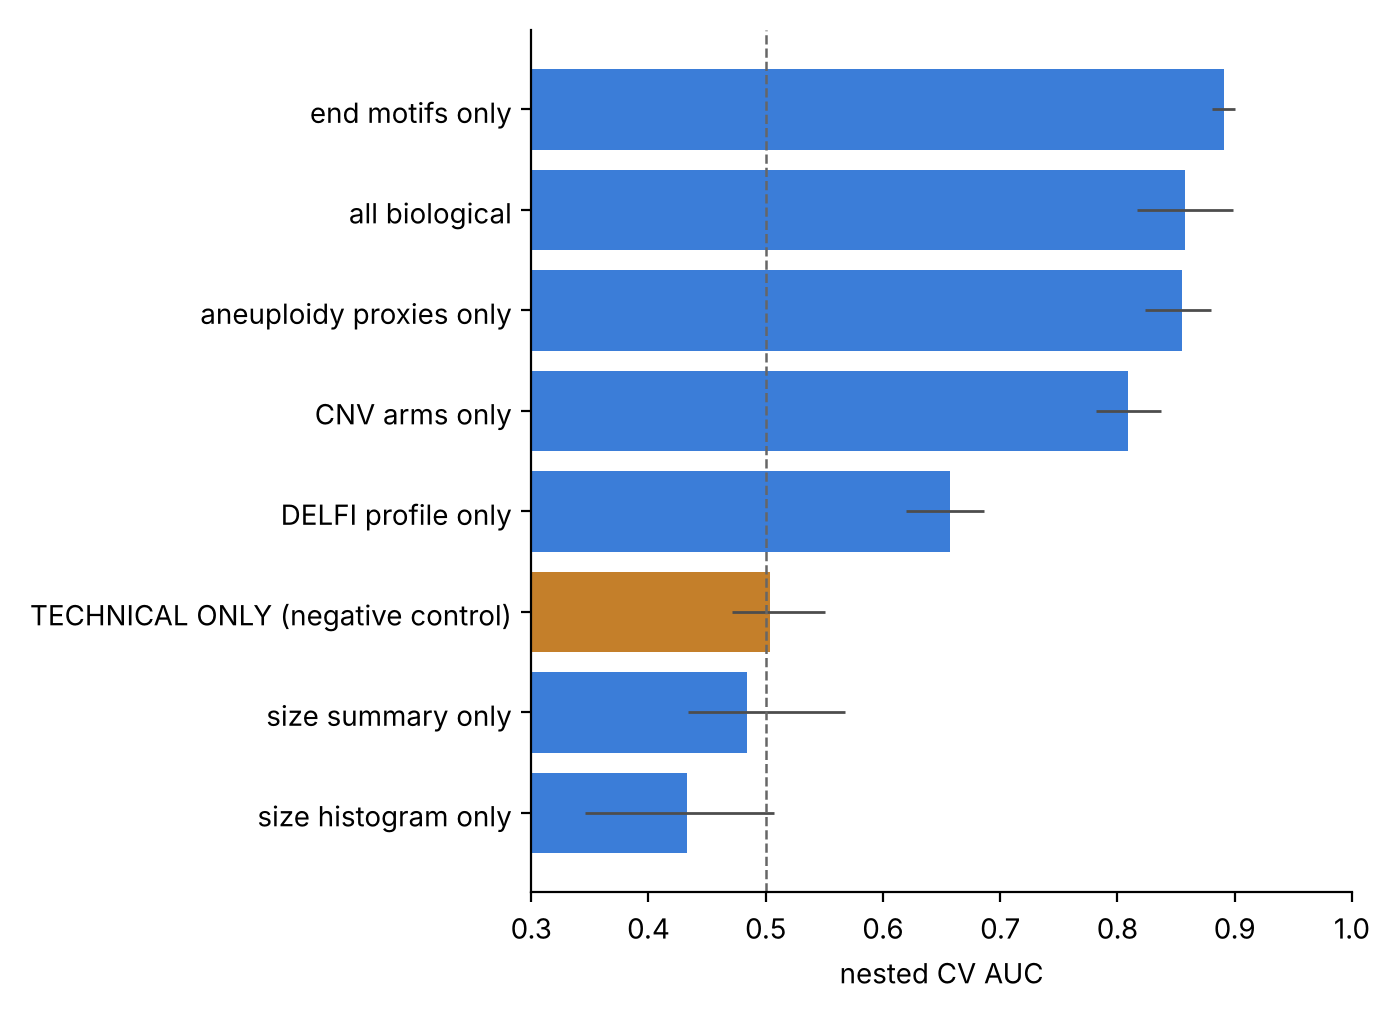

In [4]:
plots.plot_ablation(abl, '/tmp/abl.png'); Image('/tmp/abl.png')

Two features beat 1193. The three fragment-size blocks are at or below
chance.

## Negative control

A model trained only on library metrics: fragment count, its log, median
MAPQ, fraction of empty bins. It should be at chance. Judged against its
own permutation null rather than a fixed threshold, because at n=66 the
null AUC has a standard deviation near 0.09.

In [5]:
Xt = modeling.assemble_matrix(blocks, ['technical'], order)
obs = float(abl.loc[abl['label'].str.contains('TECHNICAL'),
                    'auc_mean'].iloc[0])
p, mu, sd = modeling.null_pvalue(Xt, y, obs, n_perm=30)
print(f'technical AUC {obs:.3f}; null {mu:.3f} +/- {sd:.3f}; p = {p:.3g}')

technical AUC 0.503; null 0.507 +/- 0.083; p = 0.548


## Full model

In [6]:
bio = [b for b in ('size_summary','size_hist','delfi','cnv','motif',
                   'aneuploidy') if b in blocks]
X = modeling.assemble_matrix(blocks, bio, order)
res = modeling.nested_cv(X, y, n_repeats=4, label='full')
lo, hi = res.auc_ci
print(f'AUC {res.auc_mean:.3f}  [{lo:.3f}, {hi:.3f}]  ({X.shape[1]} features, n={len(y)})')

AUC 0.858  [0.817, 0.899]  (1193 features, n=66)


## Permutation null

The whole nested CV is re-run under shuffled labels. Permuting labels and
reusing a model fit on the true ones would test nothing.

null mean 0.496, sd 0.090; observed 0.858; p = 0.01639


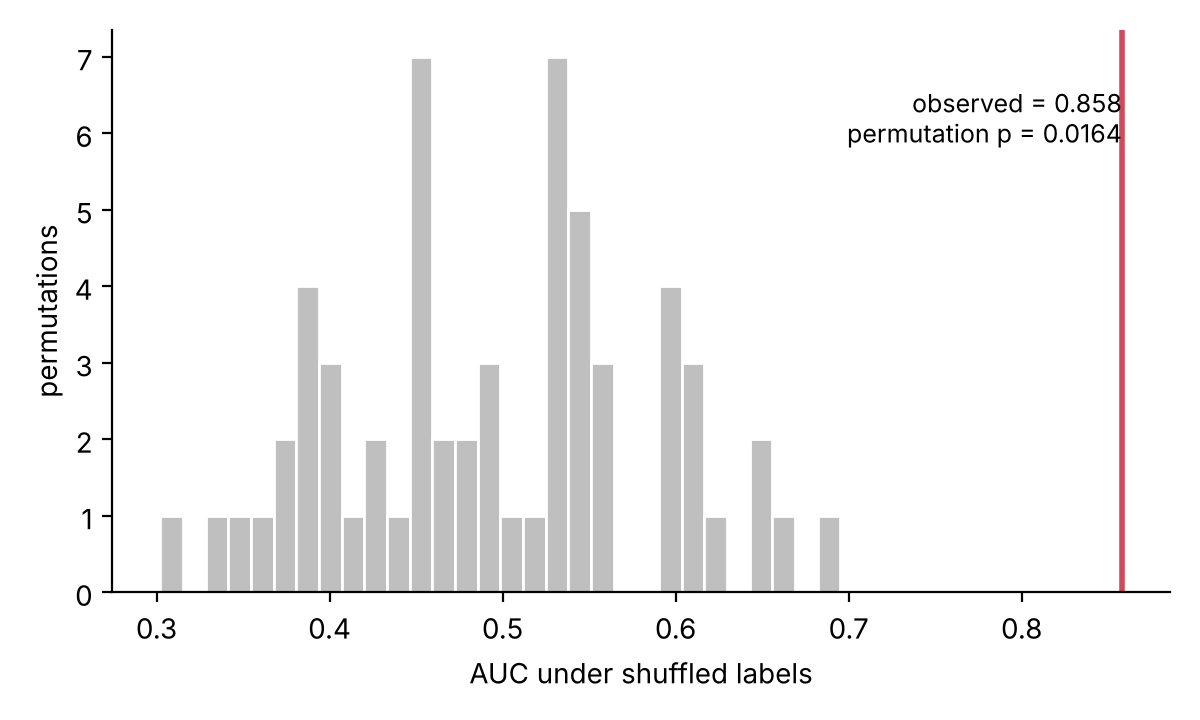

In [7]:
null, p = modeling.permutation_null(X, y, n_perm=60, n_repeats=1)
print(f'null mean {null.mean():.3f}, sd {null.std():.3f}; '
      f'observed {res.auc_mean:.3f}; p = {p:.4g}')
plots.plot_permutation_null(null, res.auc_mean, p, '/tmp/perm.png')
Image('/tmp/perm.png')

## How much does the CNV reference panel leak?

The `cnv` block above was built from a reference fit over every healthy
sample, test folds included. Each test-fold healthy sample is therefore
about 1/n of the reference it is later scored against. Rebuilding the
reference inside each training fold gives the honest number.

In [8]:
cov = blocks['coverage'].reindex(order)
fs = modeling.nested_cv_foldsafe_cnv(cov, arms, y, n_repeats=2)
leaky = float(abl.loc[abl['label'] == 'CNV arms only', 'auc_mean'].iloc[0])
print(f'whole-cohort reference: {leaky:.3f}')
print(f'fold-safe reference:    {fs.auc_mean:.3f}')
print(f'leak:                   {leaky - fs.auc_mean:+.3f}')

whole-cohort reference: 0.809
fold-safe reference:    0.669
leak:                   +0.140


## Is the end-motif signal independent?

End motifs score highest in the ablation. But 4-mers are read off the
reference at fragment ends, so a sample whose coverage has been
redistributed by arm-level gains and losses samples a different mix of
sequence context, and its spectrum shifts with no change in nuclease
activity. Partialling out chromosome entropy tests that.

In [9]:
import importlib.util
spec = importlib.util.spec_from_file_location(
    'audit', '../scripts/04_confounder_audit.py')
audit = importlib.util.module_from_spec(spec); spec.loader.exec_module(audit)

ent = blocks['aneuploidy'].reindex(order)['an_chr_entropy'].to_numpy(float)
Xm = modeling.assemble_matrix(blocks, ['motif'], order)
raw = modeling.nested_cv(Xm, y, n_repeats=3).auc_mean
adj = modeling.nested_cv(audit.residualise(Xm, ent), y, n_repeats=3).auc_mean
print(f'end motifs raw:               {raw:.3f}')
print(f'end motifs, entropy removed:  {adj:.3f}')

end motifs raw:               0.889
end motifs, entropy removed:  0.616


The motif block is largely a second measurement of copy number, not an
independent modality.

Note that the reverse adjustment is not interpretable: partialling out
aneuploidy *raises* the fragment-size blocks, and raises the negative
control along with them, because aneuploidy is downstream of the label and
conditioning on a mediator induces association. `04_confounder_audit.py`
checks for this automatically.

## Learning curve and generalisation

In [10]:
modeling.learning_curve(X, y).round(3)

,fraction,n,n_pos,n_neg,auc_mean,auc_sd
0,0.4,26,13,13,0.723,0.080
1,0.6,40,20,20,0.776,0.069
2,0.8,52,26,26,0.861,0.032
3,1.0,66,33,33,0.835,0.014


In [11]:
g = ('crag_' + samples['cancer_type']).to_numpy()
cs = modeling.cross_study_cv(X, y, g, label='leave-one-cancer-type-out')
print(f'held-out cancer type: {cs.auc_mean:.3f}')
print(cs.extra['per_study_auc'])

held-out cancer type: 0.824
{'crag_breast': 0.7727999999999999, 'crag_liver': 0.96875}


Trained on breast and tested on liver the model holds up, which argues the
signal is not breast-specific. It is not cross-cohort validation: same lab,
same protocol, same five batches.

## What the model uses

In [12]:
final = modeling.fit_final(X, y)
modeling.coefficient_report(final, list(X.columns), top_n=15).round(3)

,feature,coef,abs_coef
750,delfi_chr12:85000000,-0.164,0.164
920,cnv_arm_chr4q,-0.134,0.134
1148,motif_TCCC,0.134,0.134
588,delfi_chr6:125000000,0.133,0.133
410,delfi_chr2:20000000,0.125,0.125
897,cnv_arm_chr13q,-0.125,0.125
961,motif_ACGG,0.124,0.124
924,cnv_arm_chr6q,-0.122,0.122
580,delfi_chr6:85000000,-0.121,0.121
1144,motif_TCAC,0.116,0.116
